# Prediction, projection and grouping in one experiment

What can experimental settings predict, and what do patterns in those settings mean without an outcome label?

Proposed 2027; calendar dates pending.


# One experiment, four different objectives
Before running, name the features, continuous target and binary label. Explain why the measured yield must not enter a predictor used before the experiment.

In [1]:
import numpy as np
from demo import make_data, fit_regression, fit_standardizer, fit_logistic, sigmoid, metrics, rmse, fit_pca, fit_two_centers, run
x, yield_mg, success, train, test = make_data()
print("Features:", x.shape, "training:", len(train), "test:", len(test))
assert not set(train) & set(test)
print("First setting (C, min):", x[train[0]])

Features: (150, 2) training: 100 test: 50
First setting (C, min): [75.23664496  4.0291016 ]


Required scaffold: create the design matrix and evaluate a regression fitted only on training rows. Predict the units of the coefficients and RMSE before printing them.

In [2]:
coef = fit_regression(x[train], yield_mg[train])
test_design = np.column_stack([np.ones(len(test)), x[test]])
predicted = test_design @ coef
baseline = np.full(len(test), yield_mg[train].mean())
print("Coefficients [mg, mg/C, mg/min]:", coef)
print("Model RMSE (mg):", rmse(yield_mg[test], predicted))
print("Constant RMSE (mg):", rmse(yield_mg[test], baseline))

Coefficients [mg, mg/C, mg/min]: [1.75871639 0.04313243 1.23827624]
Model RMSE (mg): 0.8515871898654934
Constant RMSE (mg): 1.2944131531733676


Fit preprocessing only on training rows, then use the same transform for test rows. The classifier optimizer is supplied; required work is to explain this split and interpret its counts.

In [3]:
mean, scale = fit_standardizer(x[train])
z_train = (x[train] - mean) / scale
z_test = (x[test] - mean) / scale
(w, b), history = fit_logistic(z_train, success[train], steps=1800, rate=0.1, penalty=0.001)
probability = sigmoid(z_test @ w + b)
classification_report = metrics(success[test], probability, threshold=0.5)
print(classification_report)

{'threshold': 0.5, 'confusion_rows_actual_cols_predicted': [[17, 12], [5, 16]], 'accuracy': 0.66, 'precision_class1': 0.5714285714285714, 'recall_class1': 0.7619047619047619, 'sample_count': 50}


Calculate the three metrics from the displayed counts before running this check. Handle a zero denominator explicitly rather than silently inventing a percentage.

In [4]:
counts = np.array(classification_report["confusion_rows_actual_cols_predicted"])
tn, fp, fn, tp = counts.ravel()
accuracy = (tn + tp) / counts.sum()
precision = tp / (tp + fp) if tp + fp else None
recall = tp / (tp + fn) if tp + fn else None
print("Accuracy, precision, recall:", accuracy, precision, recall)

Accuracy, precision, recall: 0.66 0.5714285714285714 0.7619047619047619


PCA and clustering use the training input coordinates without success labels. Predict what is retained when only the first principal direction is kept.

In [5]:
pca = fit_pca(z_train)
scores = (z_train - pca["center"]) @ pca["components"].T
clusters = fit_two_centers(z_train)
print("Score shape:", scores.shape)
print("PC1 variance fraction:", pca["variance_ratio"][0])
print("Cluster sizes (IDs arbitrary):", np.bincount(clusters["labels"]))

Score shape: (100, 2)
PC1 variance fraction: 0.5274613216676958
Cluster sizes (IDs arbitrary): [50 50]


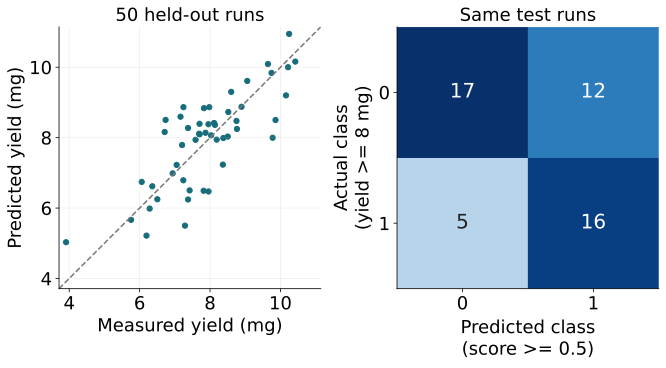

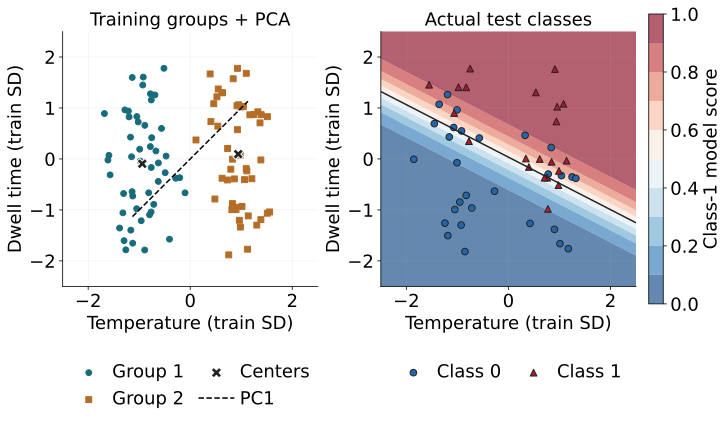

In [6]:
from IPython.display import SVG, display
report = run()
display(SVG(filename="heldout-predictions.svg"))
display(SVG(filename="projection-groups-classification.svg"))

Controlled modification: express dwell time in seconds and temperature in kelvin, then fit a training scaler in those units. Predict the standardized coordinates before executing. This tests units, not an additional model selection round.

In [7]:
converted = x * np.array([1.0, 60.0]) + np.array([273.15, 0.0])
converted_mean, converted_scale = fit_standardizer(converted[train])
converted_test = (converted[test] - converted_mean) / converted_scale
assert np.allclose(converted_test, z_test)
print("Standardized coordinates preserved by the unit conversion.")

Standardized coordinates preserved by the unit conversion.


Restart and run all cells. Write a bounded report with both baselines, all metric denominators, the separate purpose of PCA/clustering, and one reason synthetic test performance does not establish performance on a new process.